In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score)
from xgboost import XGBClassifier

from features import clean_data, build_pipeline

df = clean_data(pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"))
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn", "customerID"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [2]:
lazy_accuracy = 1 - y_test.mean()
print("Accuracy of a model that always says 'Stay':", round(lazy_accuracy, 3))

Accuracy of a model that always says 'Stay': 0.735


In [3]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print("Imbalance ratio neg/pos:", round(neg / pos, 2))

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=neg / pos, eval_metric="logloss",
                             random_state=42),
}

Imbalance ratio neg/pos: 2.77


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    scores = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in scoring}})
    print("done:", name)

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)
results

done: Logistic Regression
done: Decision Tree
done: Random Forest
done: XGBoost


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.750,0.518,0.796,0.628,0.846
3,XGBoost,0.758,0.530,0.768,0.627,0.844
1,Decision Tree,0.744,0.513,0.769,0.615,0.828
2,Random Forest,0.786,0.635,0.461,0.534,0.826


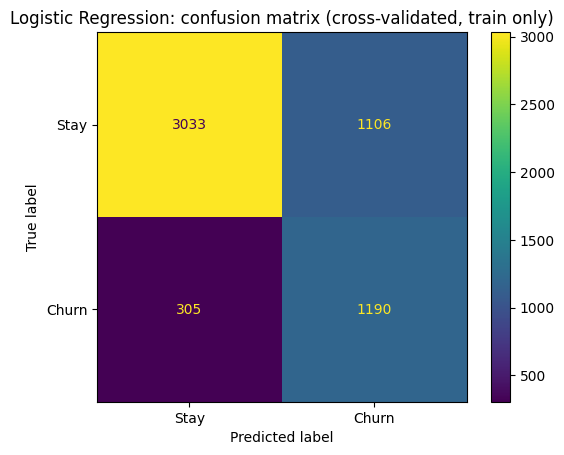

              precision    recall  f1-score   support

        Stay       0.91      0.73      0.81      4139
       Churn       0.52      0.80      0.63      1495

    accuracy                           0.75      5634
   macro avg       0.71      0.76      0.72      5634
weighted avg       0.81      0.75      0.76      5634



In [5]:
pipe = build_pipeline(models["Logistic Regression"])
oof_proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["Stay", "Churn"])
plt.title("Logistic Regression: confusion matrix (cross-validated, train only)")
plt.show()

print(classification_report(y_train, oof_pred, target_names=["Stay", "Churn"]))

In [7]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p).ravel()
    rows.append({"threshold": t,
                 "precision": round(tp / (tp + fp), 3),
                 "recall": round(tp / (tp + fn), 3),
                 "customers_flagged": int(tp + fp)})
pd.DataFrame(rows)

,threshold,precision,recall,customers_flagged
0,0.2,0.390,0.954,3656
1,0.3,0.425,0.924,3247
2,0.4,0.469,0.864,2754
3,0.5,0.518,0.796,2296
4,0.6,0.571,0.714,1871
5,0.7,0.638,0.577,1352


In [8]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
}

search = RandomizedSearchCV(build_pipeline(models["XGBoost"]), param_dist, n_iter=20,
                            scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 3))

Best params: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.85}
Best CV ROC-AUC: 0.849


TEST ROC-AUC: 0.847
              precision    recall  f1-score   support

        Stay       0.91      0.73      0.81      1035
       Churn       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



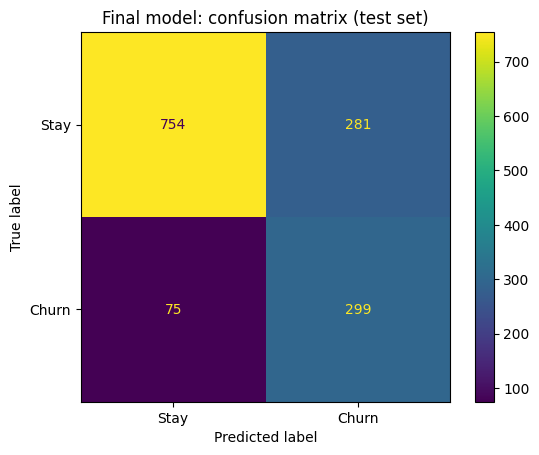

In [9]:
best = search.best_estimator_

proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("TEST ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred, target_names=["Stay", "Churn"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stay", "Churn"])
plt.title("Final model: confusion matrix (test set)")
plt.show()

## Modeling summary
- Baseline "always stay" accuracy = 73.5%, so accuracy alone is misleading.
- 4 models compared with stratified 5-fold CV on the training set.
- Class imbalance handled with class weights (balanced / scale_pos_weight).
- Best CV ROC-AUC: [model] = 0.8X. [Comment: was the simple model competitive?]
- Tuned XGBoost with RandomizedSearchCV (20 combinations): CV ROC-AUC 0.8X.
- Test set used once: ROC-AUC 0.8X, recall X%, precision X% for the churn class.
- Threshold trade-off: lowering it from 0.5 to 0.3 raises recall from X to X but flags X more customers.